**STEP 1: Setup YOLOv5 Environment**

In [ ]:
# Clone YOLOv5 repository and install requirements
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
%pip install -qr requirements.txt
import torch
from IPython.display import Image, clear_output

print(f"Setup complete. Using torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'CPU'})")

Cloning into 'yolov5'...
remote: Enumerating objects: 18248, done.
remote: Counting objects: 100% (128/128), done.
remote: Compressing objects: 100% (113/113), done.
remote: Total 18248 (delta 40), reused 31 (delta 15), pack-reused 18120 (from 1)
Receiving objects: 100% (18248/18248), 17.48 MiB | 18.65 MiB/s, done.
Resolving deltas: 100% (12389/12389), done.
/content/yolov5/yolov5
Setup complete. Using torch 2.11.0+cu128 (Tesla T4)


**STEP 2: Download the Kaggle Dataset**

You will need your kaggle.json file (from Kaggle Account Settings). This code uploads your key and downloads the specific dataset you found.


**Steps to Get your Kaggle API Token**

1. Go to Kaggle and log in.
2. Click on your profile picture (top right) Settings.
3. Scroll down to the API section and click Create New Legacy API Token.
4. This will download a file named kaggle.json. Keep this file ready.

In [ ]:
from google.colab import files
files.upload()  # Upload your kaggle.json here

# Setup Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download and unzip the sign language dataset
!kaggle datasets download -d harshvardhan21/sign-language-detection-using-images
!unzip -o sign-language-detection-using-images.zip -d /content/raw_data

Streaming output truncated to the last 5000 lines.
  inflating: /content/raw_data/data/V/819.jpg  
  inflating: /content/raw_data/data/V/82.jpg  
  inflating: /content/raw_data/data/V/820.jpg  
  inflating: /content/raw_data/data/V/821.jpg  
  inflating: /content/raw_data/data/V/822.jpg  
  inflating: /content/raw_data/data/V/823.jpg  
  inflating: /content/raw_data/data/V/824.jpg  
  inflating: /content/raw_data/data/V/825.jpg  
  inflating: /content/raw_data/data/V/826.jpg  
  inflating: /content/raw_data/data/V/827.jpg  
  inflating: /content/raw_data/data/V/828.jpg  
  inflating: /content/raw_data/data/V/829.jpg  
  inflating: /content/raw_data/data/V/83.jpg  
  inflating: /content/raw_data/data/V/830.jpg  
  inflating: /content/raw_data/data/V/831.jpg  
  inflating: /content/raw_data/data/V/832.jpg  
  inflating: /content/raw_data/data/V/833.jpg  
  inflating: /content/raw_data/data/V/834.jpg  
  inflating: /content/raw_data/data/V/835.jpg  
  inflating: /content/raw_data/data/V/8

**STEP 3: Auto-Labelling**

Transforms the folder-based Kaggle data into the image+label format required by YOLOv5.


In [ ]:
# Step #3: Stratified Sampling (100 images per class to reach 2k training samples)
import os
import random
from PIL import Image

raw_dir = '/content/raw_data/data'
processed_dir = '/content/sign_lang_yolo'
classes = sorted(os.listdir(raw_dir))

# Create YOLO directory structure
for split in ['train', 'val']:
    for folder in ['images', 'labels']:
        os.makedirs(os.path.join(processed_dir, split, folder), exist_ok=True)

# Process exactly 100 images per class to yield ~2,000+ training images total
for idx, cls in enumerate(classes):
    cls_path = os.path.join(raw_dir, cls)
    all_imgs = [f for f in os.listdir(cls_path) if f.endswith(('.jpg', '.png', '.jpeg'))]

    # CHANGED: Increased from 60 to 100 to scale total training pool up
    sample_size = min(100, len(all_imgs))
    sampled_imgs = random.sample(all_imgs, sample_size)

    # 80% train (80 images), 20% val (20 images) per class
    split_pt = int(sample_size * 0.8)

    for i, img_name in enumerate(sampled_imgs):
        subset = 'train' if i < split_pt else 'val'

        # Copy image and create .txt label
        with Image.open(os.path.join(cls_path, img_name)) as img:
            new_name = f"{cls}_{img_name}"
            img.save(os.path.join(processed_dir, subset, 'images', new_name))

            label_path = os.path.join(processed_dir, subset, 'labels', new_name.rsplit('.', 1)[0] + '.txt')
            with open(label_path, 'w') as f:
                f.write(f"{idx} 0.5 0.5 0.8 0.8") # <class> <x> <y> <w> <h>

print(f"Dataset preparation complete. Limited to 100 images per class across {len(classes)} classes.")

Dataset preparation complete. Limited to 100 images per class across 35 classes.


**STEP 4: Create Configuration YAML**

Tells the *train.py* script where your data lives and what the letters are.


In [ ]:
import os
import random

train_path = '/content/sign_lang_yolo/train/images'
all_images = [os.path.join(train_path, f) for f in os.listdir(train_path) if f.endswith(('.jpg', '.png', '.jpeg'))]

# This will now successfully grab exactly 2,000 images because len(all_images) > 2000
subset_count = min(2000, len(all_images))
subset_images = random.sample(all_images, subset_count)

# Save these paths to a text file
subset_file = '/content/sign_lang_yolo/train_subset.txt'
with open(subset_file, 'w') as f:
    for img_path in subset_images:
        f.write(img_path + '\n')

print(f"Created subset list with {subset_count} images at {subset_file}")

Created subset list with 2000 images at /content/sign_lang_yolo/train_subset.txt


**STEP 5: Training Command**

Run the training using Small variant (yolov5s.pt)

In [ ]:
import os
import random
import yaml


# 2. Setup Paths
train_path = '/content/sign_lang_yolo/train/images'
val_path = '/content/sign_lang_yolo/val/images'

# 3. Helper to create subset lists2
def create_subset(src_path, filename, count):
    all_imgs = [os.path.join(src_path, f) for f in os.listdir(src_path) if f.endswith(('.jpg', '.png', '.jpeg'))]
    subset = random.sample(all_imgs, min(count, len(all_imgs)))
    with open(filename, 'w') as f:
        for img in subset:
            f.write(img + '\n')
    return os.path.abspath(filename)

# CHANGED: Update subset creation to 2000 for training, and 200 for validation
train_list = create_subset(train_path, 'subset_train.txt', 2000)
val_list = create_subset(val_path, 'subset_val.txt', 200)

# 2. Update YAML (Ensure 'classes' is defined earlier in your notebook)
config = {
  'train': train_list,
  'val': val_list,
  'nc': len(classes),
  'names': classes
}

# Fix: Save data.yaml to the correct directory where train.py expects it
with open('data.yaml', 'w') as f:
    yaml.dump(config, f)


In [ ]:
# 3. Optimized Training Command
# NOTE: If you hit an out-of-memory error, change "--batch 32" to "--batch 16"
!python train.py --img 416 --batch 32 --epochs 100 --data data.yaml --weights yolov5s.pt --workers 4

#prototype
#!python train.py --img 640 --batch 16 --epochs 5 --data data.yaml --weights yolov5s.pt

Streaming output truncated to the last 5000 lines.
      62/99       3.9G    0.01467   0.005704    0.02346         81        416:  17% 11/63 [00:02<00:14,  3.69it/s]/content/yolov5/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      62/99       3.9G     0.0147   0.005762    0.02269         93        416:  19% 12/63 [00:03<00:14,  3.57it/s]/content/yolov5/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      62/99       3.9G    0.01483   0.005835    0.02262         93        416:  21% 13/63 [00:03<00:14,  3.47it/s]/content/yolov5/yolov5/train.py:414: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(amp):
      62/99     

**STEP 6: Evaluation and Inference**

Check the performance and test the model on images it has never seen.

In [ ]:
import IPython
import os

# Display training results
results_image_path = 'runs/train/exp/results.png'
if os.path.exists(results_image_path):
    print(f"Displaying training results from {results_image_path}")
    IPython.display.Image(filename=results_image_path, width=1000)
else:
    print(f"Warning: Training results image '{results_image_path}' not found. "
          "This typically happens if the training in the previous step did not complete successfully.")

# Run detection on test images
!python detect.py --weights runs/train/exp/weights/best.pt --img 416 --conf 0.25 --source /content/sign_lang_yolo/val/images

Displaying training results from runs/train/exp/results.png
detect: weights=['runs/train/exp/weights/best.pt'], source=/content/sign_lang_yolo/val/images, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.25, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, visualize=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-496-g0fd7ea49 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 157 layers, 7104520 parameters, 0 gradients, 16.0 GFLOPs
image 1/1386 /content/sign_lang_yolo/val/images/1_10.jpg: 416x416 1 1, 7.2ms
image 2/1386 /content/sign_lang_yolo/val/images/1_1025.jpg: 416x416 1 1, 7.3ms
image 3/1386 /content/sign_lang_yolo/val/images/1_1049.jpg: 416x416 1 1, 7.2ms
ima

In [ ]:
import os
from IPython.display import Image

detection_results_dir = 'runs/detect/exp'

# List contents of the detection results directory
print(f"Contents of '{detection_results_dir}':")
for item in os.listdir(detection_results_dir):
    print(item)

# Display a sample detected image (assuming there's at least one .jpg or .png file)
# You might need to adjust this to pick a specific image if there are many
image_files = [f for f in os.listdir(detection_results_dir) if f.endswith(('.jpg', '.png', '.jpeg'))]

if image_files:
    sample_image_path = os.path.join(detection_results_dir, image_files[0])
    print(f"\nDisplaying a sample detected image: {sample_image_path}")
    Image(filename=sample_image_path, width=800)
else:
    print("No image files found in the detection results directory to display.")

Contents of 'runs/detect/exp':
A_446.jpg
H_691.jpg
Z_725.jpg
G_391.jpg
1_964.jpg
M_496.jpg
9_715.jpg
R_552.jpg
V_900.jpg
Q_347.jpg
2_25.jpg
C_690.jpg
J_270.jpg
3_573.jpg
V_969.jpg
B_1135.jpg
T_474.jpg
N_683.jpg
1_115.jpg
I_559.jpg
4_561.jpg
Q_657.jpg
6_577.jpg
X_251.jpg
J_335.jpg
L_223.jpg
B_620.jpg
8_997.jpg
L_645.jpg
D_838.jpg
G_812.jpg
Z_1127.jpg
W_452.jpg
B_621.jpg
P_641.jpg
V_638.jpg
V_200.jpg
D_571.jpg
4_1132.jpg
B_9.jpg
1_474.jpg
K_941.jpg
1_511.jpg
V_396.jpg
Y_819.jpg
Y_60.jpg
B_700.jpg
A_965.jpg
F_289.jpg
R_916.jpg
8_191.jpg
8_985.jpg
J_1076.jpg
1_485.jpg
W_477.jpg
H_572.jpg
K_561.jpg
9_829.jpg
3_387.jpg
R_224.jpg
P_729.jpg
K_442.jpg
S_965.jpg
A_1094.jpg
P_312.jpg
P_875.jpg
5_630.jpg
V_408.jpg
N_267.jpg
6_827.jpg
E_212.jpg
5_747.jpg
J_841.jpg
M_890.jpg
N_82.jpg
C_1075.jpg
L_429.jpg
8_155.jpg
Q_369.jpg
D_848.jpg
M_559.jpg
Z_217.jpg
I_874.jpg
H_829.jpg
G_842.jpg
P_771.jpg
4_450.jpg
M_746.jpg
B_49.jpg
8_633.jpg
T_132.jpg
T_847.jpg
O_326.jpg
R_150.jpg
1_1049.jpg
N_755.jpg
X_1101.j

STEP 7: Graph

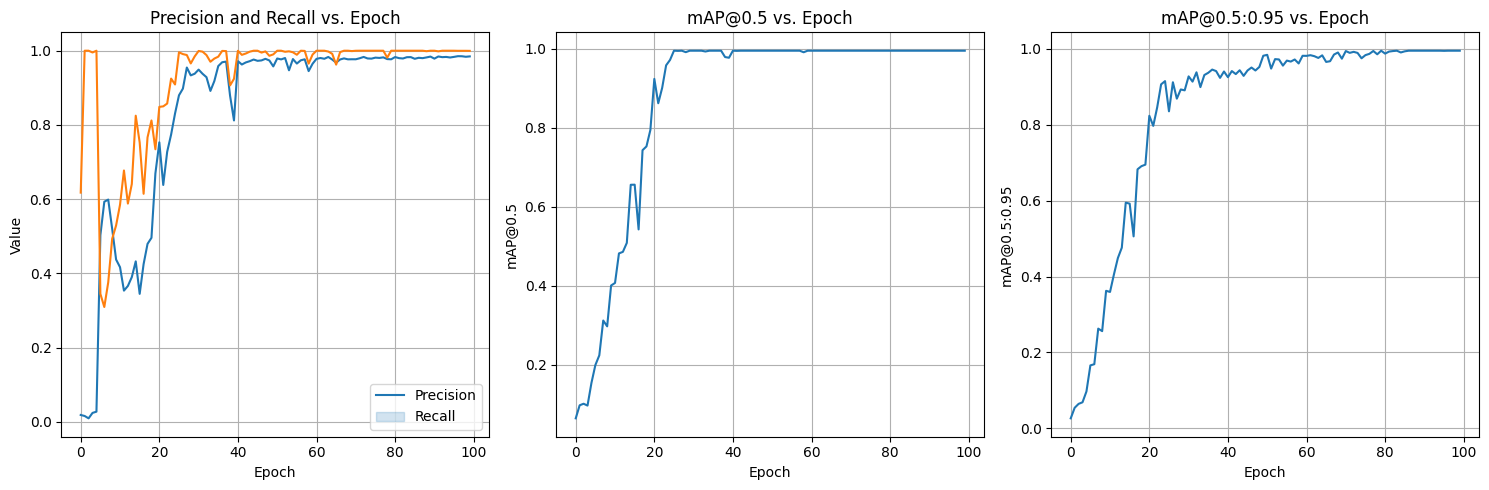

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the results CSV file
results_path = 'runs/train/exp/results.csv'
results_df = pd.read_csv(results_path)

# Clean column names (remove leading spaces if present)
# The original YOLOv5 results.csv can sometimes have a leading space, this ensures they are clean
results_df.columns = results_df.columns.str.strip()

# Plotting training metrics
plt.figure(figsize=(15, 5))

# Subplot for Precision and Recall
plt.subplot(1, 3, 1)
sns.lineplot(data=results_df, x='epoch', y='metrics/precision')
sns.lineplot(data=results_df, x='epoch', y='metrics/recall')
plt.title('Precision and Recall vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend(['Precision', 'Recall'])
plt.grid(True)

# Subplot for mAP_0.5
plt.subplot(1, 3, 2)
sns.lineplot(data=results_df, x='epoch', y='metrics/mAP_0.5')
plt.title('mAP@0.5 vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('mAP@0.5')
plt.grid(True)

# Subplot for mAP_0.5:0.95
plt.subplot(1, 3, 3)
sns.lineplot(data=results_df, x='epoch', y='metrics/mAP_0.5:0.95')
plt.title('mAP@0.5:0.95 vs. Epoch')
plt.xlabel('Epoch')
plt.ylabel('mAP@0.5:0.95')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
